# Vectorized Operations
- NumPy’s ND-arrays are homogeneous: an array can only contain data of a single type. 
- For instance, an array can contain 8-bit integers or 32-bit floating point numbers, but not a mix of the two. 
- This is in stark contrast to Python’s lists and tuples, which are entirely unrestricted in the variety of contents they can possess; a given list could simultaneously contain strings, integers, and other objects. 
- This restriction on an array’s contents comes at a great benefit; in “knowing” that an array’s contents are homogeneous in data type, NumPy is able to delegate the task of performing mathematical operations on the array’s contents to optimized, compiled C code. This is a process that is referred to as vectorization. 
- The outcome of this can be a tremendous speedup relative to the analogous computation performed in Python, which must painstakingly check the data type of every one of the items as it iterates over the arrays, since Python typically works with lists with unrestricted contents.

In [31]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import time
import matplotlib.pyplot as plt

In [32]:
v1 = np.random.rand(1000000, 1)
v2 = np.random.rand(1000000, 1)

# Multiplication by a Scalar

In [33]:
#Scaling a vector by a constant is important in processes like normalization. 
#Quite often, there are for-loop implementations used, which take unnecessary amounts of time.

In [34]:
# Scaling Vector - For loop
start = time.process_time()
v1_scaled = np.zeros((1000000, 1))

for i in range(len(v1)):
    v1_scaled[i] = 2 * v1[i]

end = time.process_time()
    
print("Scaling vector Answer = " + str(v1_scaled))
print("Time taken = " + str(1000*(end - start)) + " ms")  

Scaling vector Answer = [[0.62146059]
 [0.99082399]
 [0.55209506]
 ...
 [0.52045349]
 [0.24653004]
 [0.42445729]]
Time taken = 1921.875 ms


In [35]:
#Scaling Vector - Vectorized
start = time.process_time()
v1_scaled = np.zeros((1000000, 1))

v1_scaled = 2 * v1

end = time.process_time()
    
print("Scaling vector Answer = " + str(v1_scaled))
print("Time taken = " + str(1000*(end - start)) + " ms")  

Scaling vector Answer = [[0.62146059]
 [0.99082399]
 [0.55209506]
 ...
 [0.52045349]
 [0.24653004]
 [0.42445729]]
Time taken = 0.0 ms


# Dot Products
Now we are going to perform the dot product of the two vectors.It is basically multiplying the two vectors element wise and then summing all of the elements. Here is the for loop implementation.
This is the formula used to multiply the different values of the features of a training example and the weights that the model has learned. In deep learning, this process is repeated lots and lots of times. Even simple algorithms like Linear Regression make use of this a lot.


In [36]:
# Dot product For loop
start = time.process_time()
product = 0


for i in range(len(v1)):
    product += v1[i] * v2[i]

end = time.process_time()

print("Dot product Answer = " + str(product))
print("Time taken = " + str(1000*(end - start)) + " ms")

Dot product Answer = [249518.68287134]
Time taken = 2265.625 ms


In [10]:
#vectorized implementation

In [37]:
#Dot product Vectorized
start = time.process_time()
product = 0

product = np.dot(v1.T, v2)

end = time.process_time()

print("Dot product Answer = " + str(product))
print("Time taken = " + str(1000*(end - start)) + " ms")

Dot product Answer = [[249518.68287134]]
Time taken = 31.25 ms


# Element Wise multiplication

In [39]:
#Element wise mutliplication For loop
start = time.process_time()

answer = np.zeros((1000000, 1))

for i in range(len(v1)):
    answer[i] = v1[i] * v2[i]
    
end = time.process_time()

print("Element Wise answer = " + str(answer))
print("Time Taken = " + str(1000*(end - start)) + " ms")

Element Wise answer = [[0.17597212]
 [0.04407117]
 [0.0802811 ]
 ...
 [0.22198101]
 [0.08113706]
 [0.13862373]]
Time Taken = 1484.375 ms


In [40]:
#Element wise multiplication Vectorized
start = time.process_time()

answer = np.zeros((1000000, 1))

answer = v1 * v2

end = time.process_time()

print("Element Wise answer = " + str(answer))
print("Time Taken = " + str(1000*(end - start)) + " ms")

Element Wise answer = [[0.17597212]
 [0.04407117]
 [0.0802811 ]
 ...
 [0.22198101]
 [0.08113706]
 [0.13862373]]
Time Taken = 0.0 ms


# Element Wise Matrix Multiplication

In [41]:
#Element wise matrix multiplication For loop

m1 = np.random.rand(10000, 10000)
m2 = np.random.rand(10000, 10000)
answer = np.zeros((10000, 10000))

start = time.process_time()

for i in range(m1.shape[0]):
    for j in range(m1.shape[1]):
        answer[i, j] = m1[i, j] * m2[i, j]
    
end = time.process_time()

print("Element Wise Matrix answer = " + str(answer))
print("Time Taken = " + str(1000*(end - start)) + " ms")

Element Wise Matrix answer = [[0.01765233 0.07210457 0.34299852 ... 0.03168443 0.24417807 0.23325797]
 [0.03835462 0.10811899 0.00695587 ... 0.29388269 0.35668511 0.28681492]
 [0.04257242 0.11878758 0.4363589  ... 0.42924869 0.03589325 0.09955975]
 ...
 [0.03024853 0.28410198 0.35157686 ... 0.3625136  0.28105176 0.13556429]
 [0.06301768 0.4845579  0.75645245 ... 0.73628395 0.59270944 0.19294945]
 [0.18984205 0.05540534 0.17610798 ... 0.03238889 0.07911082 0.1341284 ]]
Time Taken = 67640.625 ms


In [42]:
#Element wise matrix multiplication Vectorized
answer = np.zeros((10000, 10000))

start = time.process_time()

answer = np.multiply(m1, m2)

end = time.process_time()

print("Element Wise Matrix answer = " + str(answer))
print("Time Taken = " + str(1000*(end - start)) + " ms")

Element Wise Matrix answer = [[0.01765233 0.07210457 0.34299852 ... 0.03168443 0.24417807 0.23325797]
 [0.03835462 0.10811899 0.00695587 ... 0.29388269 0.35668511 0.28681492]
 [0.04257242 0.11878758 0.4363589  ... 0.42924869 0.03589325 0.09955975]
 ...
 [0.03024853 0.28410198 0.35157686 ... 0.3625136  0.28105176 0.13556429]
 [0.06301768 0.4845579  0.75645245 ... 0.73628395 0.59270944 0.19294945]
 [0.18984205 0.05540534 0.17610798 ... 0.03238889 0.07911082 0.1341284 ]]
Time Taken = 359.375 ms


# Time-complexity Plot

In [48]:
sizes = [10, 100, 1000, 10000, 100000, 1000000, 10000000]
complexity = pd.DataFrame(columns=['sizes', 'for_loop', 'numpy'])
complexity['sizes'] = sizes

In [49]:
for_loops = []
numpy = []

for size in sizes:
    v1 = np.random.rand(size, 1)
    v2 = np.random.rand(size, 1)
    
    #For loop implementation
    start = time.process_time()
    product = 0

    for i in range(len(v1)):
        product += v1[i] * v2[i]

    end = time.process_time()
    
    for_loops.append(1000*(end-start))
    
    #Vectorized implementation
    
    start = time.process_time()
    product = 0

    product = np.dot(v1.T, v2)

    end = time.process_time()
    numpy.append(1000*(end - start))

In [50]:
complexity['for_loop'] = for_loops
complexity['numpy'] = numpy
complexity

,sizes,for_loop,numpy
0,10,0.000,0.00
1,100,0.000,0.00
2,1000,15.625,0.00
3,10000,15.625,0.00
4,100000,421.875,0.00
5,1000000,2437.500,0.00
6,10000000,21968.750,31.25


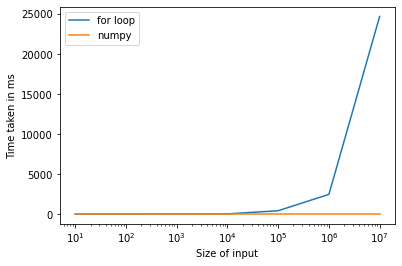

In [20]:
plt.plot(complexity['sizes'], complexity['for_loops'])
plt.plot(complexity['sizes'], complexity['numpy'])

plt.xscale(value='log')
plt.xlabel("Size of input")
plt.ylabel("Time taken in ms")
plt.legend(['for loop', 'numpy'])
plt.show()